# Visualisasi Data Laundry Sepatu

## 1. Import Libraries

- `pandas` digunakan untuk membaca dan mengolah data berbentuk tabel.
- `matplotlib` digunakan untuk membuat grafik.
- Pengaturan tampilan di bawah membuat teks, ukuran grafik, dan tata letak lebih mudah dibaca.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Pengaturan tampilan tabel agar seluruh baris dapat ditampilkan
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

# Pengaturan tampilan grafik
plt.rcParams["figure.figsize"] = (10, 5.5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["font.size"] = 10
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

## 2. Menghubungkan Google Drive dan membaca dataset

Kode menggunakan lokasi file yang sudah ditentukan untuk menghubungkan Google Drive, membaca file CSV, lalu menampilkan seluruh data dalam bentuk tabel.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

# Lokasi dataset yang sudah dibersihkan
file_path = "/content/drive/MyDrive/DatminT2_2418023/Data_Bersih_Laundry_Sepatu.csv"

# Membaca dataset
df = pd.read_csv(file_path)

print("Dataset berhasil dibaca.")
print(f"Jumlah baris: {df.shape[0]}")
print(f"Jumlah kolom: {df.shape[1]}")

display(df)

Mounted at /content/drive
Dataset berhasil dibaca.
Jumlah baris: 120
Jumlah kolom: 13


,id_order,nama_pelanggan,tanggal_order,jenis_sepatu,bahan_sepatu,tingkat_kekotoran,jenis_layanan,lama_pengerjaan,biaya_rp,kasir,bulan_order,kategori_biaya,estimasi_lama_hari
0,CS001,Maya,2026-03-21,Sepatu Futsal,Mesh,Berat,Cuci Reguler,24 jam,48000,Bang Bagus,March,Rendah,1.00
1,CS002,Maya,2026-06-18,Sneakers,Kanvas,Ringan,Cuci Reguler,24 jam,36000,Mba Ayu,June,Rendah,1.00
2,CS003,Dani,2026-01-08,Sneakers,Kanvas,Ringan,Unyellowing,24 jam,0,Bang Bagus,January,Rendah,1.00
3,CS004,Maya,2026-04-18,Sepatu Futsal,Kulit,Sedang,Repaint,3 jam,143000,Bang Bagus,April,Tinggi,0.12
4,CS005,Dea,2026-05-26,Sepatu Kanvas,Kanvas,Sedang,Repaint,13 jam,86000,Bang Bagus,May,Sedang,0.54
5,CS006,Fania,2026-01-20,Sepatu Kulit,Kulit,Ringan,Repaint,24 jam,131000,Bang Bagus,January,Tinggi,1.00
6,CS007,Rakhis,2026-04-06,Sepatu Sekolah,Kanvas,Ringan,Unyellowing,3 jam,34000,Kak Rian,April,Rendah,0.12
7,CS008,Dea,2026-05-23,Boots,Mesh,Ringan,Repaint,24 jam,120000,Bang Dedi,May,Tinggi,1.00
8,CS009,Maya,2026-05-24,Sneakers,Kulit,Sedang,Deep Clean,72 jam,109000,Kak Rian,May,Tinggi,3.00
9,CS010,Isa,2026-05-26,Boots,Kanvas,Ringan,Cuci Reguler,72 jam,49000,Bang Bagus,May,Rendah,3.00


## 3. Memeriksa struktur dan kualitas data

Bagian ini menampilkan nama kolom, tipe data, jumlah nilai kosong, dan ringkasan statistik biaya. Pemeriksaan ini digunakan untuk membantu memahami dataset sebelum divisualisasikan.

In [ ]:
print("INFORMASI DATASET")
df.info()

print("\\nJUMLAH DATA KOSONG PER KOLOM")
display(df.isna().sum().rename("Jumlah data kosong").to_frame())

print("\\nRINGKASAN STATISTIK BIAYA")
display(df["biaya_rp"].describe().to_frame())

INFORMASI DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_order            120 non-null    object 
 1   nama_pelanggan      120 non-null    object 
 2   tanggal_order       120 non-null    object 
 3   jenis_sepatu        120 non-null    object 
 4   bahan_sepatu        120 non-null    object 
 5   tingkat_kekotoran   120 non-null    object 
 6   jenis_layanan       120 non-null    object 
 7   lama_pengerjaan     120 non-null    object 
 8   biaya_rp            120 non-null    int64  
 9   kasir               120 non-null    object 
 10  bulan_order         120 non-null    object 
 11  kategori_biaya      120 non-null    object 
 12  estimasi_lama_hari  120 non-null    float64
dtypes: float64(1), int64(1), object(11)
memory usage: 12.3+ KB
\nJUMLAH DATA KOSONG PER KOLOM


,Jumlah data kosong
id_order,0
nama_pelanggan,0
tanggal_order,0
jenis_sepatu,0
bahan_sepatu,0
tingkat_kekotoran,0
jenis_layanan,0
lama_pengerjaan,0
biaya_rp,0
kasir,0


\nRINGKASAN STATISTIK BIAYA


,biaya_rp
count,120.000000
mean,83025.000000
std,43839.942361
min,0.000000
25%,38000.000000
50%,99500.000000
75%,124250.000000
max,147000.000000


## 4. Menyiapkan data untuk visualisasi

Kolom tanggal diubah menjadi format tanggal.Kolom `pendapatan` menggunakan nilai pada `biaya_rp` sebagai nilai nominal transaksi.

**Catatan:** Pada tahap data cleansing, nilai biaya dengan keterangan ‘Gratis’ diubah menjadi angka 0 agar format data menjadi konsisten dan memudahkan proses pengolahan serta visualisasi

In [ ]:
# Mengubah tanggal menjadi format tanggal
df["tanggal_order"] = pd.to_datetime(df["tanggal_order"], errors="coerce")

# Nilai nominal transaksi yang digunakan dalam visualisasi
df["pendapatan"] = pd.to_numeric(df["biaya_rp"], errors="coerce")

nama_bulan = {
    1: "January", 2: "February", 3: "March",
    4: "April", 5: "May", 6: "June",
    7: "July", 8: "August", 9: "September",
    10: "October", 11: "November", 12: "December"
}

df["nomor_bulan"] = df["tanggal_order"].dt.month
df["nama_bulan"] = df["nomor_bulan"].map(nama_bulan)

urutan_bulan = list(nama_bulan.values())

print("Periode data:",
      df["tanggal_order"].min().strftime("%d-%m-%Y") if df["tanggal_order"].notna().any() else "Tidak tersedia",
      "sampai",
      df["tanggal_order"].max().strftime("%d-%m-%Y") if df["tanggal_order"].notna().any() else "Tidak tersedia")
print("Jumlah order dengan biaya Rp0:", int((df["biaya_rp"] == 0).sum()))

Periode data: 01-01-2026 sampai 08-09-2026
Jumlah order dengan biaya Rp0: 1


## 5. Visualisasi 1 — Jumlah order per bulan

Grafik batang digunakan untuk membandingkan jumlah order pada setiap bulan. Batang yang lebih tinggi berarti terdapat lebih banyak order pada bulan tersebut.

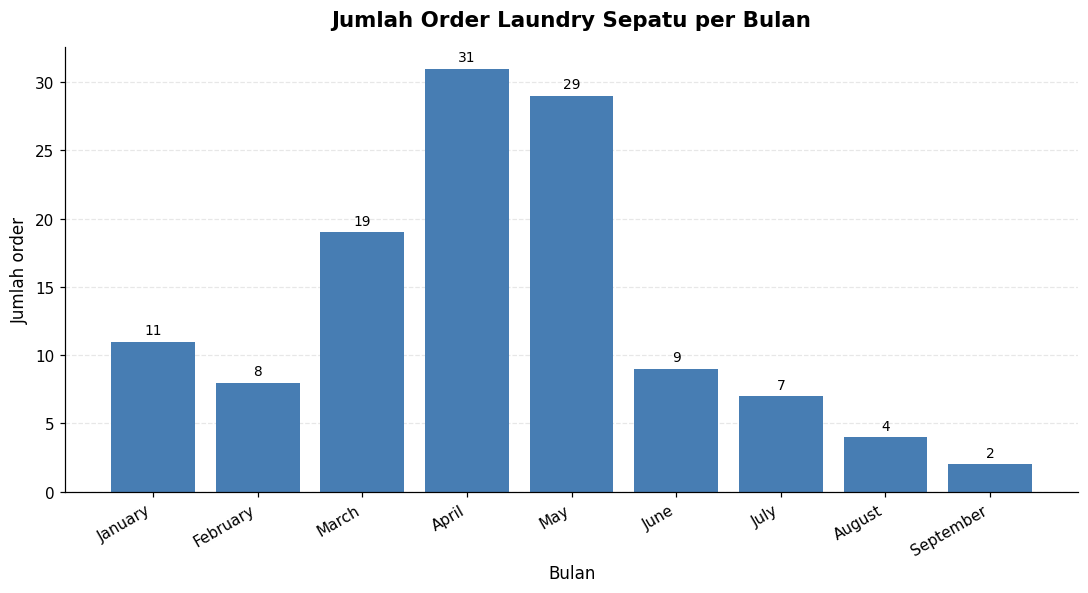

In [ ]:
order_bulanan = (
    df.dropna(subset=["nomor_bulan"])
      .groupby(["nomor_bulan", "nama_bulan"])
      .size()
      .reset_index(name="jumlah_order")
      .sort_values("nomor_bulan")
)

fig, ax = plt.subplots()
batang = ax.bar(order_bulanan["nama_bulan"], order_bulanan["jumlah_order"], color="#477DB3")
ax.bar_label(batang, padding=3, fontsize=9)
ax.set_title("Jumlah Order Laundry Sepatu per Bulan", pad=14, weight="bold")
ax.set_xlabel("Bulan")
ax.set_ylabel("Jumlah order")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 6. Visualisasi 2 — Total nominal biaya order per bulan

Grafik garis memperlihatkan perubahan total nominal biaya order dari bulan ke bulan. Nilai ini dihitung dengan menjumlahkan kolom `biaya_rp` pada setiap bulan.

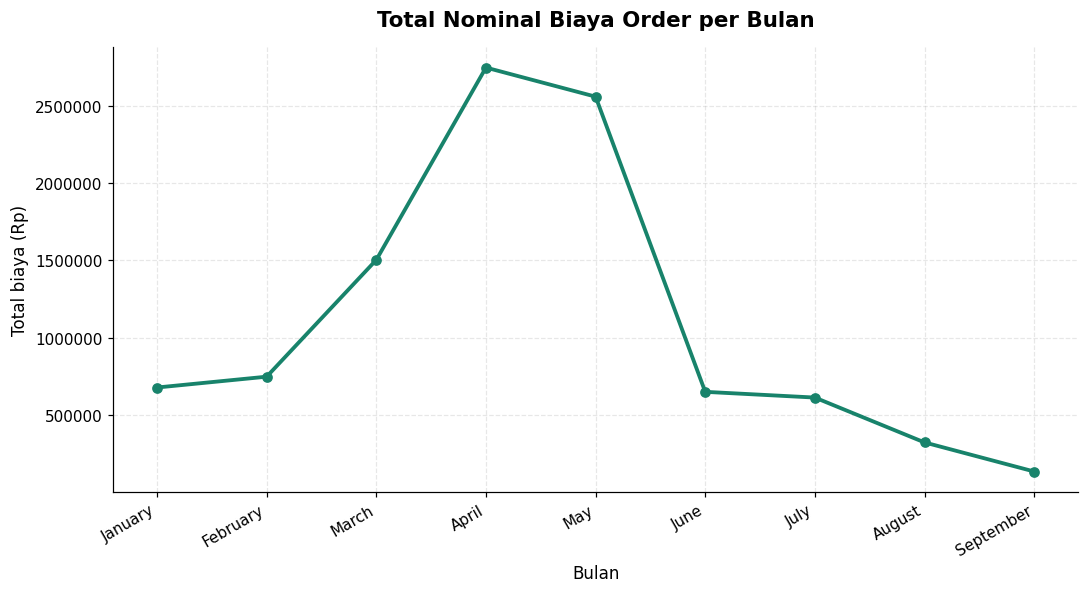

In [ ]:
biaya_bulanan = (
    df.dropna(subset=["nomor_bulan"])
      .groupby(["nomor_bulan", "nama_bulan"])["pendapatan"]
      .sum()
      .reset_index()
      .sort_values("nomor_bulan")
)

fig, ax = plt.subplots()
ax.plot(biaya_bulanan["nama_bulan"], biaya_bulanan["pendapatan"],
        marker="o", linewidth=2.5, color="#18836B")
ax.set_title("Total Nominal Biaya Order per Bulan", pad=14, weight="bold")
ax.set_xlabel("Bulan")
ax.set_ylabel("Total biaya (Rp)")
ax.ticklabel_format(style="plain", axis="y")
ax.grid(True, linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 7. Visualisasi 3 — Total biaya berdasarkan jenis layanan

Grafik batang horizontal membandingkan total nominal biaya order dari setiap jenis layanan. Batang terpanjang menunjukkan layanan dengan jumlah biaya tercatat paling besar pada dataset, bukan otomatis layanan yang paling menguntungkan.

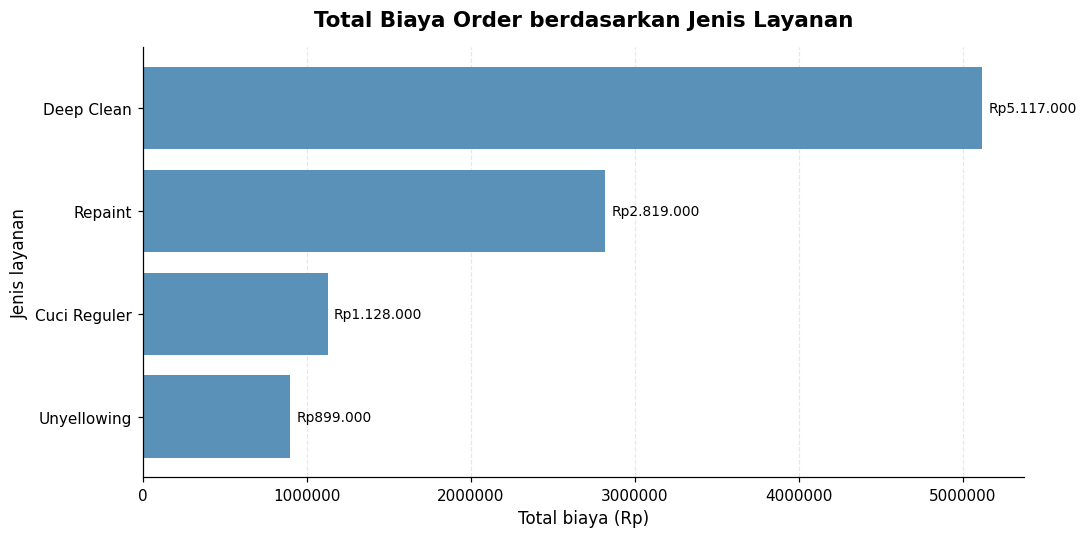

In [ ]:
biaya_layanan = df.groupby("jenis_layanan")["pendapatan"].sum().sort_values()

fig, ax = plt.subplots(figsize=(10, max(5, len(biaya_layanan) * 0.55)))
batang = ax.barh(biaya_layanan.index.astype(str), biaya_layanan.values, color="#5A91B8")
ax.bar_label(batang, labels=[f"Rp{nilai:,.0f}".replace(",", ".") for nilai in biaya_layanan.values],
             padding=4, fontsize=9)
ax.set_title("Total Biaya Order berdasarkan Jenis Layanan", pad=14, weight="bold")
ax.set_xlabel("Total biaya (Rp)")
ax.set_ylabel("Jenis layanan")
ax.ticklabel_format(style="plain", axis="x")
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## 8. Visualisasi 4 — Jumlah order berdasarkan jenis sepatu

Grafik ini menunjukkan jenis sepatu yang paling sering muncul pada transaksi. Batang tertinggi menunjukkan kategori sepatu dengan jumlah order terbanyak.

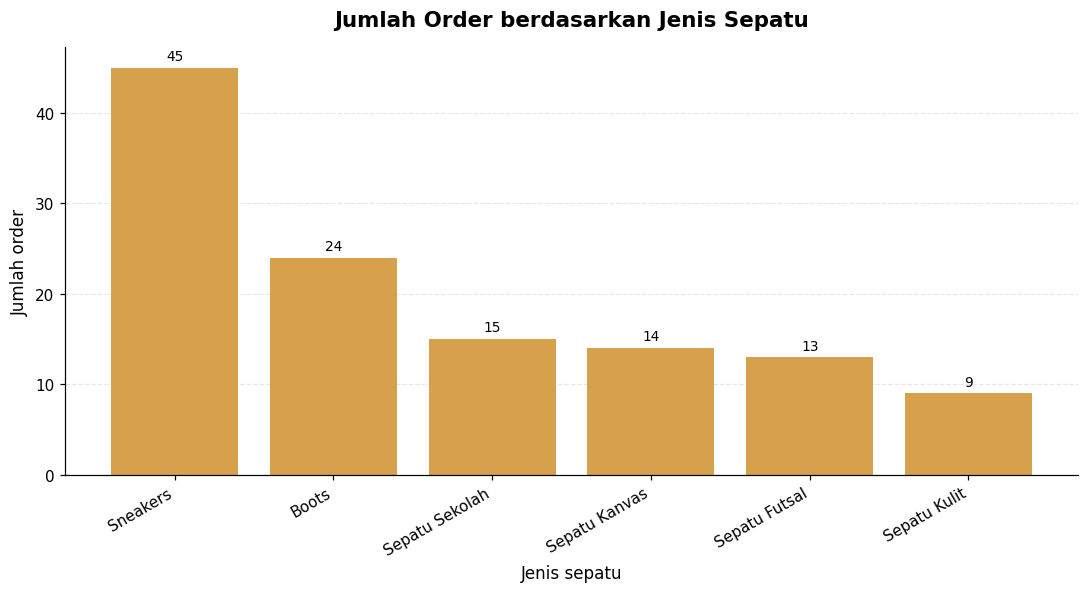

In [ ]:
jumlah_sepatu = df["jenis_sepatu"].fillna("Tidak diketahui").value_counts().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 5.5))
batang = ax.bar(jumlah_sepatu.index.astype(str), jumlah_sepatu.values, color="#D6A04D")
ax.bar_label(batang, padding=3, fontsize=9)
ax.set_title("Jumlah Order berdasarkan Jenis Sepatu", pad=14, weight="bold")
ax.set_xlabel("Jenis sepatu")
ax.set_ylabel("Jumlah order")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 9. Visualisasi 5 — Jumlah order berdasarkan tingkat kekotoran

Grafik batang membandingkan jumlah order berdasarkan tingkat kekotoran sepatu. Grafik ini membantu melihat kategori kekotoran yang paling sering tercatat.

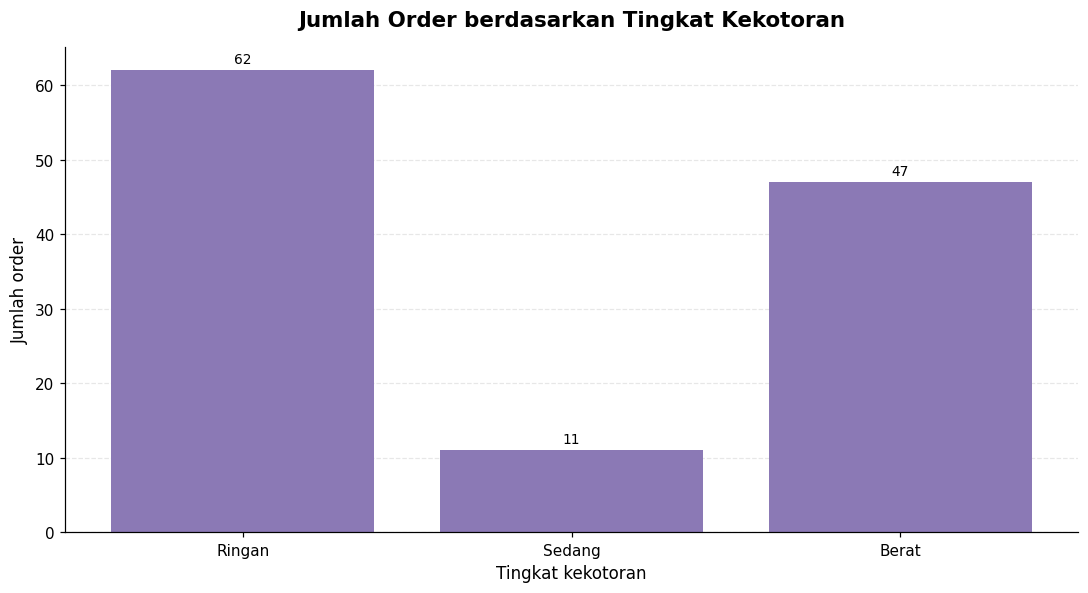

In [ ]:
urutan_kotor = ["Ringan", "Sedang", "Berat"]
jumlah_kotor = df["tingkat_kekotoran"].fillna("Tidak diketahui").value_counts()
kategori_ada = [k for k in urutan_kotor if k in jumlah_kotor.index]
kategori_ada += [k for k in jumlah_kotor.index if k not in urutan_kotor]
jumlah_kotor = jumlah_kotor.reindex(kategori_ada)

fig, ax = plt.subplots()
batang = ax.bar(jumlah_kotor.index.astype(str), jumlah_kotor.values, color="#8B79B5")
ax.bar_label(batang, padding=3, fontsize=9)
ax.set_title("Jumlah Order berdasarkan Tingkat Kekotoran", pad=14, weight="bold")
ax.set_xlabel("Tingkat kekotoran")
ax.set_ylabel("Jumlah order")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## 10. Visualisasi 6 — Jumlah order berdasarkan bahan sepatu

Grafik ini membandingkan banyaknya order untuk setiap bahan sepatu. Kategori bahan dengan batang tertinggi paling sering muncul pada transaksi.

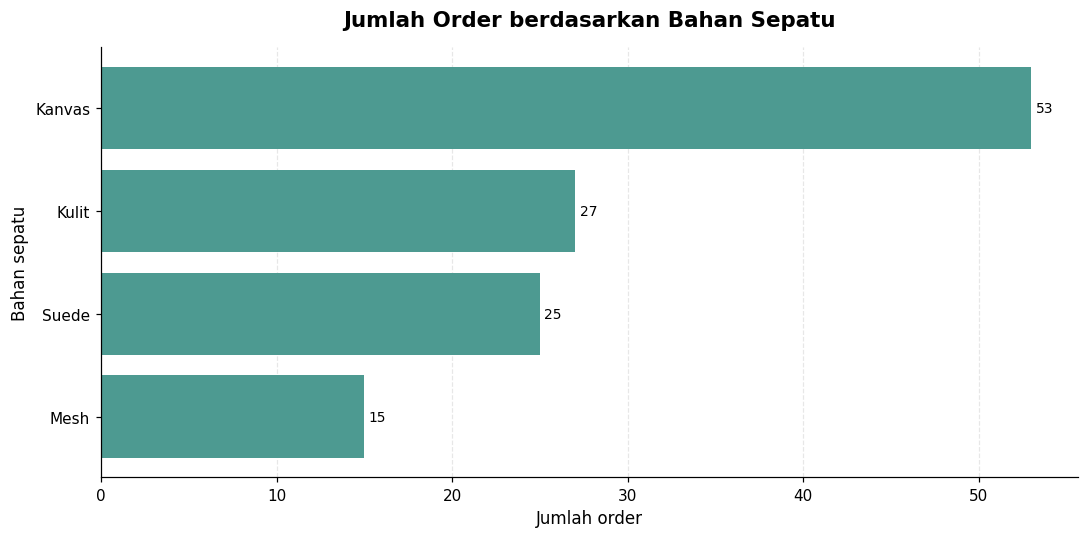

In [ ]:
jumlah_bahan = df["bahan_sepatu"].fillna("Tidak diketahui").value_counts().sort_values()

fig, ax = plt.subplots(figsize=(10, max(5, len(jumlah_bahan) * 0.45)))
batang = ax.barh(jumlah_bahan.index.astype(str), jumlah_bahan.values, color="#4D9A91")
ax.bar_label(batang, padding=3, fontsize=9)
ax.set_title("Jumlah Order berdasarkan Bahan Sepatu", pad=14, weight="bold")
ax.set_xlabel("Jumlah order")
ax.set_ylabel("Bahan sepatu")
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## 11. Visualisasi 7 — Sebaran biaya per order

Histogram menunjukkan sebaran biaya pada berbagai rentang nilai. Garis putus-putus menandai rata-rata biaya per order.

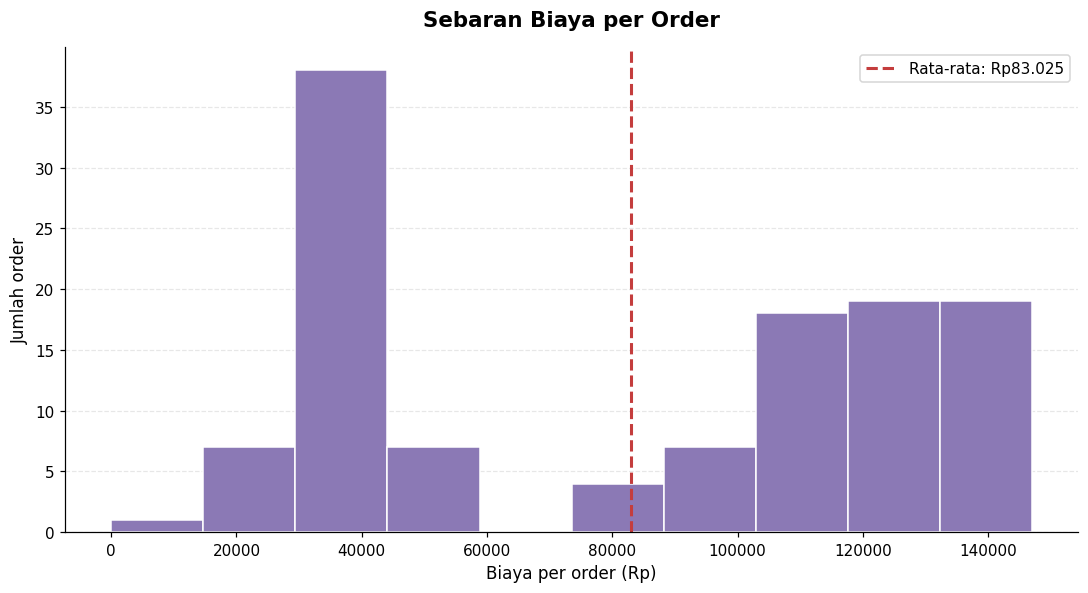

In [ ]:
biaya_valid = df["biaya_rp"].dropna()
rata_rata_biaya = biaya_valid.mean()

fig, ax = plt.subplots()
ax.hist(biaya_valid, bins=10, color="#8B79B5", edgecolor="white")
ax.axvline(rata_rata_biaya, color="#C43D3D", linestyle="--", linewidth=2,
           label=f"Rata-rata: Rp{rata_rata_biaya:,.0f}".replace(",", "."))
ax.set_title("Sebaran Biaya per Order", pad=14, weight="bold")
ax.set_xlabel("Biaya per order (Rp)")
ax.set_ylabel("Jumlah order")
ax.ticklabel_format(style="plain", axis="x")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## 13. Ringkasan hasil visualisasi

Ringkasan berikut dihitung langsung dari dataset yang dibaca. Hasil ini dapat digunakan untuk membantu menjelaskan grafik saat presentasi.

In [ ]:
total_order = len(df)
total_biaya = df["biaya_rp"].sum()
rata_rata_biaya = df["biaya_rp"].mean()

order_per_bulan = (
    df.dropna(subset=["nomor_bulan"])
      .groupby(["nomor_bulan", "nama_bulan"])
      .size()
      .sort_index()
)
biaya_per_bulan = (
    df.dropna(subset=["nomor_bulan"])
      .groupby(["nomor_bulan", "nama_bulan"])["pendapatan"]
      .sum()
      .sort_index()
)

layanan_total = df.groupby("jenis_layanan")["pendapatan"].sum()
sepatu_total = df["jenis_sepatu"].fillna("Tidak diketahui").value_counts()

print("RINGKASAN VISUALISASI DATA LAUNDRY SEPATU")
print("=" * 48)
print(f"Jumlah order                    : {total_order}")
print(f"Total nominal biaya order       : Rp{total_biaya:,.0f}".replace(",", "."))
print(f"Rata-rata biaya per order       : Rp{rata_rata_biaya:,.0f}".replace(",", "."))
if not order_per_bulan.empty:
    print(f"Bulan dengan order terbanyak    : {order_per_bulan.idxmax()[1]} ({order_per_bulan.max()} order)")
if not biaya_per_bulan.empty:
    print(f"Bulan dengan total biaya tertinggi: {biaya_per_bulan.idxmax()[1]} (Rp{biaya_per_bulan.max():,.0f})".replace(",", "."))
if not layanan_total.empty:
    print(f"Layanan dengan total biaya tertinggi: {layanan_total.idxmax()}")
if not sepatu_total.empty:
    print(f"Jenis sepatu dengan order terbanyak : {sepatu_total.idxmax()} ({sepatu_total.max()} order)")

RINGKASAN VISUALISASI DATA LAUNDRY SEPATU
Jumlah order                    : 120
Total nominal biaya order       : Rp9.963.000
Rata-rata biaya per order       : Rp83.025
Bulan dengan order terbanyak    : April (31 order)
Bulan dengan total biaya tertinggi: April (Rp2.747.000)
Layanan dengan total biaya tertinggi: Deep Clean
Jenis sepatu dengan order terbanyak : Sneakers (45 order)


## 14. Kesimpulan

Visualisasi membantu mengubah data transaksi menjadi informasi yang lebih mudah dipahami. Grafik batang digunakan untuk membandingkan kategori, grafik garis untuk melihat perubahan antarbulan, dan histogram untuk melihat sebaran biaya. Hasil grafik tetap perlu ditafsirkan sesuai kolom dan isi dataset; total biaya tercatat tidak selalu sama dengan laba karena biaya operasional tidak tersedia dalam analisis ini.